In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Project folder
BASE_DIR = Path.cwd()

print("Project folder:", BASE_DIR)
print("Explainable AI notebook setup started.")

Project folder: c:\Users\shrad\OneDrive\Desktop\60-days-data-science
Explainable AI notebook setup started.


In [4]:
# Locate the customer-risk dataset
DATA_PATH = BASE_DIR / "day41_customer_risk_scores.csv"

# Load the data
df = pd.read_csv(DATA_PATH)

# Display basic information
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (793, 12)

Available columns:
['Customer ID', 'Total_Sales', 'Total_Orders', 'Last_Order_Date', 'First_Order_Date', 'Average_Order_Value', 'Customer_Lifetime_Days', 'Recency_Days', 'Purchase_Frequency', 'Estimated_CLV', 'Risk_Score', 'Risk_Level']

First five rows:


,Customer ID,Total_Sales,Total_Orders,Last_Order_Date,First_Order_Date,Average_Order_Value,Customer_Lifetime_Days,Recency_Days,Purchase_Frequency,Estimated_CLV,Risk_Score,Risk_Level
0,AA-10315,5563.560,5,2018-06-29,2015-03-31,1112.712000,1186,184,1.538786,5136.676391,75.584806,High Risk
1,AA-10375,1056.390,9,2018-12-11,2015-04-21,117.376667,1330,19,2.469925,869.734624,-15.373195,Low Risk
2,AA-10480,1790.512,4,2018-04-15,2015-05-04,447.628000,1077,259,1.355617,1820.436992,115.579738,High Risk
3,AA-10645,5086.935,6,2018-11-05,2015-06-22,847.822500,1232,55,1.777597,4521.261222,8.819774,Medium Risk
4,AB-10015,886.156,3,2017-11-10,2015-02-18,295.385333,996,415,1.099398,974.237771,196.311177,High Risk


In [5]:
# Select the same seven features used on Day 50
feature_columns = [
    "Total_Sales",
    "Total_Orders",
    "Average_Order_Value",
    "Customer_Lifetime_Days",
    "Recency_Days",
    "Purchase_Frequency",
    "Estimated_CLV"
]

# Features and target
X = df[feature_columns]
y = df["Risk_Level"]

# Check the data
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nRisk category distribution:")
print(y.value_counts())

print("\nMissing values in selected features:")
print(X.isnull().sum())

Feature matrix shape: (793, 7)
Target shape: (793,)

Risk category distribution:
Risk_Level
Low Risk       265
High Risk      264
Medium Risk    264
Name: count, dtype: int64

Missing values in selected features:
Total_Sales               0
Total_Orders              0
Average_Order_Value       0
Customer_Lifetime_Days    0
Recency_Days              0
Purchase_Frequency        0
Estimated_CLV             0
dtype: int64


In [6]:

# Split data exactly as in Day 50
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build the Logistic Regression pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logisticregression", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Hyperparameter search
param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ["lbfgs"],
    "logisticregression__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Select the best model
best_model = grid_search.best_estimator_

# Evaluate on unseen test data
y_pred = best_model.predict(X_test)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

print("\nTest accuracy:")
print(round(accuracy_score(y_test, y_pred), 4))

print("\nTest macro F1:")
print(round(f1_score(y_test, y_pred, average="macro"), 4))


Best parameters:
{'logisticregression__C': 100, 'logisticregression__class_weight': None, 'logisticregression__solver': 'lbfgs'}

Best cross-validation macro F1:
0.981

Test accuracy:
0.9748

Test macro F1:
0.9747


In [7]:

# Extract the trained Logistic Regression model
lr_model = best_model.named_steps["logisticregression"]

# Calculate the average absolute coefficient across risk classes
importance_values = np.mean(
    np.abs(lr_model.coef_),
    axis=0
)

# Create the feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance_values
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Feature Importance Ranking:")
display(importance_df)


Feature Importance Ranking:


,Feature,Importance
0,Recency_Days,29.346570
1,Purchase_Frequency,3.058211
2,Average_Order_Value,1.004979
3,Total_Sales,0.670960
4,Total_Orders,0.659264
5,Estimated_CLV,0.361015
6,Customer_Lifetime_Days,0.252682


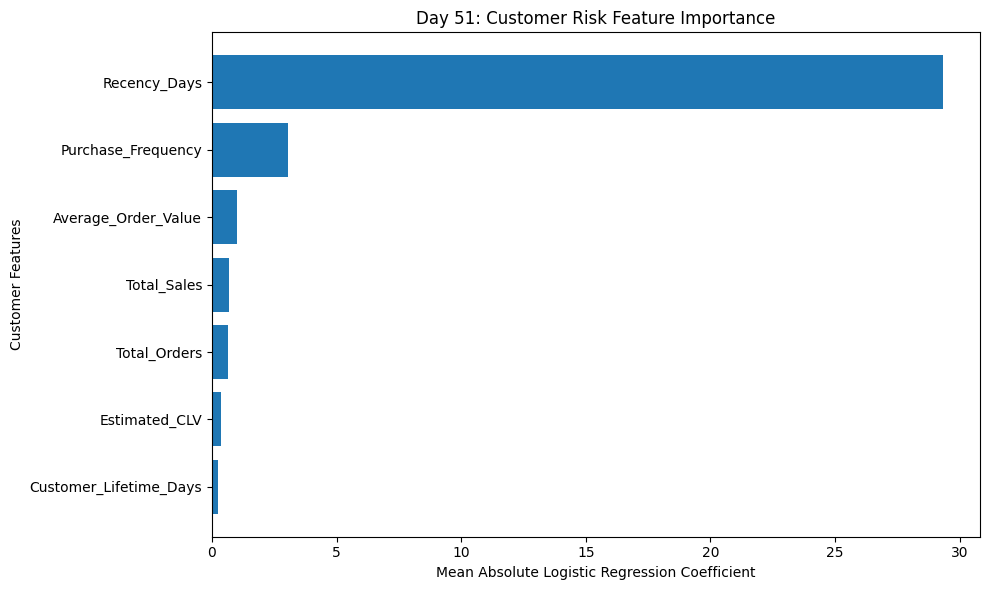

Chart saved to: c:\Users\shrad\OneDrive\Desktop\60-days-data-science\day51_feature_importance.png


In [8]:

# Create the feature importance chart
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Day 51: Customer Risk Feature Importance")
plt.xlabel("Mean Absolute Logistic Regression Coefficient")
plt.ylabel("Customer Features")
plt.tight_layout()

# Save the chart for GitHub submission
chart_path = BASE_DIR / "day51_feature_importance.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", chart_path)


In [9]:

# Examine how each feature influences each risk category
lr_model = best_model.named_steps["logisticregression"]

coefficient_df = pd.DataFrame(
    lr_model.coef_,
    columns=feature_columns,
    index=lr_model.classes_
)

print("Feature coefficients for each risk category:")
display(coefficient_df.round(4))


Feature coefficients for each risk category:


,Total_Sales,Total_Orders,Average_Order_Value,Customer_Lifetime_Days,Recency_Days,Purchase_Frequency,Estimated_CLV
High Risk,-0.4921,0.9889,0.9393,-0.3790,38.5229,-4.5701,-0.5415
Low Risk,1.0064,-0.6303,-1.5075,0.2512,-44.0199,4.5873,0.4821
Medium Risk,-0.5144,-0.3586,0.5682,0.1278,5.4970,-0.0172,0.0594


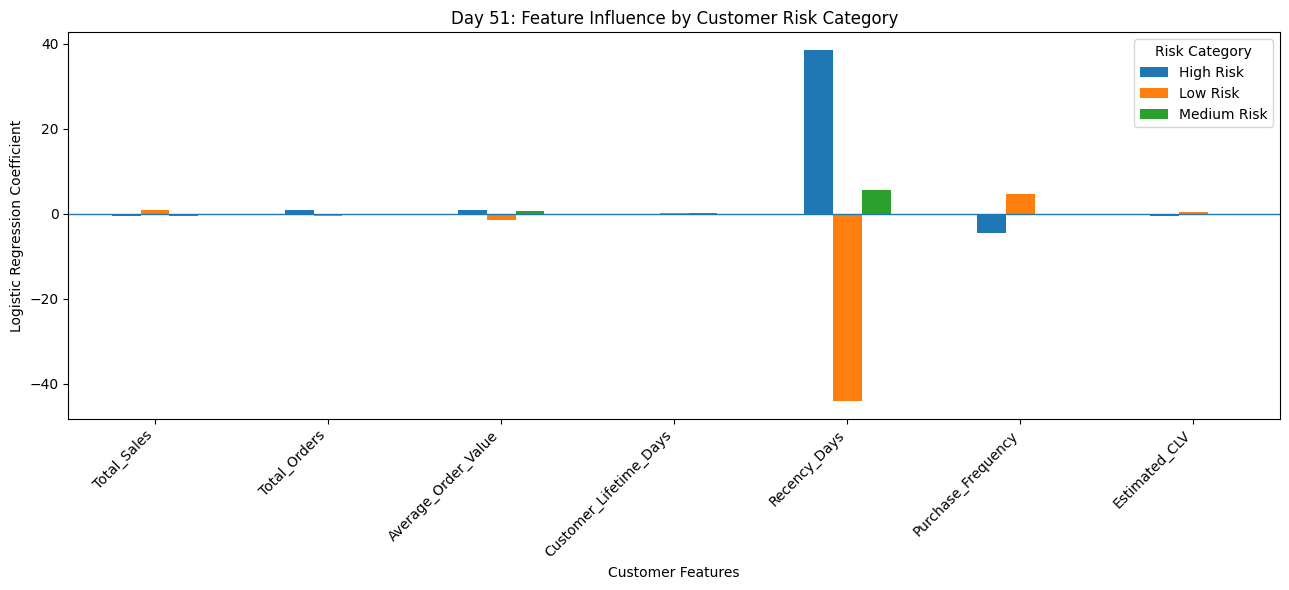

Chart saved to: c:\Users\shrad\OneDrive\Desktop\60-days-data-science\day51_risk_category_coefficients.png


In [10]:

# Plot coefficients for all three risk categories
coefficient_df.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.axhline(y=0, linewidth=1)
plt.title("Day 51: Feature Influence by Customer Risk Category")
plt.xlabel("Customer Features")
plt.ylabel("Logistic Regression Coefficient")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Risk Category")
plt.tight_layout()

# Save the chart
direction_chart_path = BASE_DIR / "day51_risk_category_coefficients.png"
plt.savefig(direction_chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", direction_chart_path)


In [11]:

# Select one customer from the test set
customer = X_test.iloc[[0]]

# Get the predicted risk category
predicted_risk = best_model.predict(customer)[0]

# Get prediction probabilities
probabilities = best_model.predict_proba(customer)[0]

# Scale the customer's feature values
scaled_customer = best_model.named_steps["scaler"].transform(customer)

# Calculate feature contributions to each class score
class_index = list(lr_model.classes_).index(predicted_risk)
contributions = scaled_customer[0] * lr_model.coef_[class_index]

# Create the explanation table
explanation_df = pd.DataFrame({
    "Feature": feature_columns,
    "Customer_Value": customer.iloc[0].values,
    "Contribution_to_Predicted_Class": contributions
})

explanation_df["Absolute_Contribution"] = (
    explanation_df["Contribution_to_Predicted_Class"].abs()
)

explanation_df = explanation_df.sort_values(
    "Absolute_Contribution",
    ascending=False
).reset_index(drop=True)

print("Predicted Risk Category:", predicted_risk)

print("\nPrediction probabilities:")
for risk, probability in zip(lr_model.classes_, probabilities):
    print(f"{risk}: {probability:.2%}")

print("\nFeature contributions for this customer:")
display(explanation_df.round(4))


Predicted Risk Category: High Risk

Prediction probabilities:
High Risk: 100.00%
Low Risk: 0.00%
Medium Risk: 0.00%

Feature contributions for this customer:


,Feature,Customer_Value,Contribution_to_Predicted_Class,Absolute_Contribution
0,Recency_Days,811.000,142.0783,142.0783
1,Total_Orders,2.000,-1.6329,1.6329
2,Purchase_Frequency,2.000,1.5796,1.5796
3,Customer_Lifetime_Days,313.000,0.8390,0.8390
4,Total_Sales,1058.616,0.3406,0.3406
5,Average_Order_Value,529.308,0.1272,0.1272
6,Estimated_CLV,3175.848,0.0186,0.0186


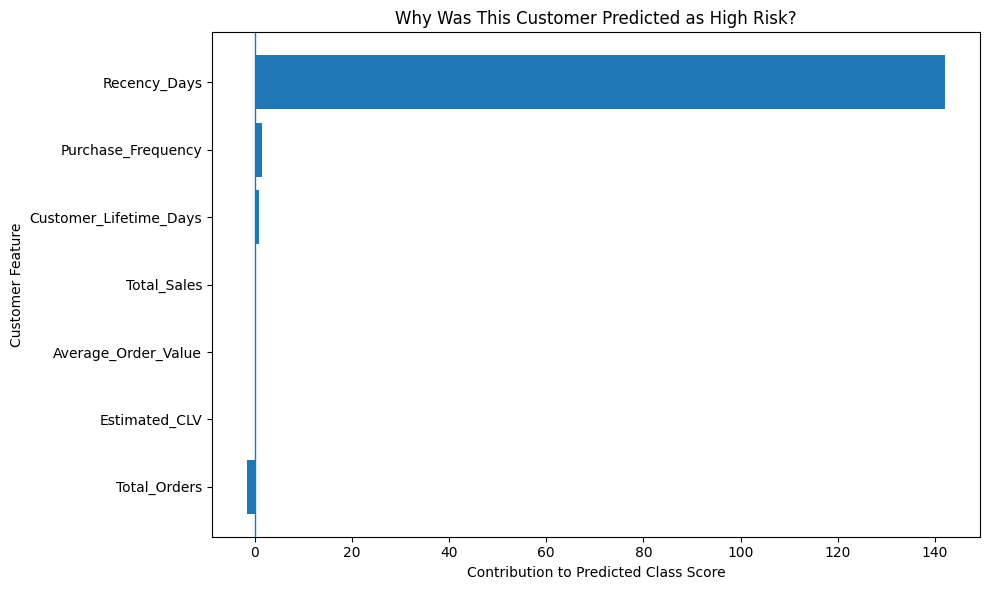

Local explanation chart saved to: c:\Users\shrad\OneDrive\Desktop\60-days-data-science\day51_local_explanation.png
Predicted category: High Risk


In [12]:

# Plot feature contributions for the selected customer
plot_df = explanation_df.sort_values(
    "Contribution_to_Predicted_Class"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Contribution_to_Predicted_Class"]
)

plt.axvline(x=0, linewidth=1)
plt.title(f"Why Was This Customer Predicted as {predicted_risk}?")
plt.xlabel("Contribution to Predicted Class Score")
plt.ylabel("Customer Feature")
plt.tight_layout()

# Save the local explanation chart
local_chart_path = BASE_DIR / "day51_local_explanation.png"
plt.savefig(local_chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Local explanation chart saved to:", local_chart_path)
print("Predicted category:", predicted_risk)
